# A kerékpárkölcsönzési adatok megismerése

Ebben a notebookban lépésenként vizsgáljuk meg az adatokat. Egy cellát kijelölés után a **Shift + Enter** billentyűkkel lehet futtatni. Felülről lefelé haladj, mert a későbbi cellák használják a korábbi cellák eredményeit.

## 1. A pandas betöltése

A pandas segítségével táblázatos adatokat tudunk beolvasni és vizsgálni. A `pd` a pandas rövid neve a kódban.

In [2]:
import pandas as pd

## 2. Az adatok beolvasása

A `read_csv` beolvassa a fájlt egy `adatok` nevű táblázatba. A `head()` alapértelmezés szerint az első öt sort mutatja meg. Próbáld ki a `head(10)` változatot is!

In [3]:
adatok = pd.read_csv("data/hour.csv")
adatok.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## 3. A táblázat mérete

A `shape` először a sorok, majd az oszlopok számát adja vissza. Egy sor egy órához tartozó megfigyelés.

In [4]:
adatok.shape

(17379, 17)

## 4. Időrendi felosztás scikit-learn segítségével

A `cnt` a megjósolandó kölcsönzésszám. A `casual` és a `registered` összege éppen a `cnt`, ezért ezeket nem szabad bemenetként használni. Az `instant` azonosító, a `dteday` pedig a rendezéshez szükséges; ezeket itt szintén kihagyjuk a modell bemenetéből.

Először dátum és óra szerint rendezzük a sorokat. A `train_test_split` a korábbi 80%-ot tanításra, a későbbi 20%-ot tesztelésre választja szét. A `shuffle=False` azt jelenti, hogy nem keverjük össze az időrendet. Az adatok további ellenőrzése és a kategóriák feldolgozása még hátravan.

In [5]:
from sklearn.model_selection import train_test_split

adatok = adatok.sort_values(["dteday", "hr"]).reset_index(drop=True)
X = adatok.drop(columns=["instant", "dteday", "casual", "registered", "cnt"])
y = adatok["cnt"]

X_tanito, X_teszt, y_tanito, y_teszt = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

print("Tanítósorok:", len(X_tanito))
print("Tesztsorok:", len(X_teszt))

Tanítósorok: 13903
Tesztsorok: 3476


## Következő lépés

Vizsgáljuk meg, mit jelentenek az oszlopok, vannak-e hiányzó értékek, és milyen ábrák segítenek megérteni az adatokat. Az adatokból tanult előfeldolgozást a tanítóadatok alapján fogjuk beállítani.

## Hiányzó értékek

Oszloponként megszámoljuk a hiányzó értékeket, hogy lássuk, szükséges-e ezek kezelése.

In [6]:
adatok.isna().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

## Ismétlődő időpontok

Megvizsgáljuk, szerepel-e ugyanaz a dátum és óra többször az adatokban.

In [7]:
adatok.duplicated(subset=["dteday", "hr"]).sum()

np.int64(0)

## A kölcsönzésszámok statisztikái

A tanítóadatokból kiszámoljuk például az átlagot, a mediánt, a minimumot és a maximumot.

In [8]:
y_tanito.describe()

count    13903.000000
mean       174.639143
std        166.955414
min          1.000000
25%         37.000000
50%        130.000000
75%        258.000000
max        957.000000
Name: cnt, dtype: float64

## A kölcsönzésszámok eloszlása

A hisztogram megmutatja, milyen gyakran fordulnak elő az egyes kölcsönzésszámok. Az ábrát megjelenítés előtt PNG-ként is elmentjük.

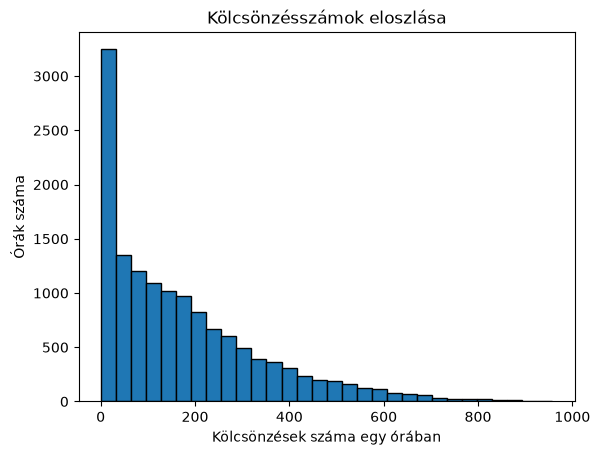

In [10]:
from pathlib import Path

Path("figures").mkdir(exist_ok=True)

import matplotlib.pyplot as plt

plt.hist(y_tanito, bins=30, edgecolor="black")
plt.xlabel("Kölcsönzések száma egy órában")
plt.ylabel("Órák száma")
plt.title("Kölcsönzésszámok eloszlása")
plt.savefig("figures/kolcsonzes_eloszlas.png", dpi=150, bbox_inches="tight")
plt.show()

## Átlagos kölcsönzésszám napszak szerint

A tanítóadatokban óránként kiszámoljuk az átlagot, hogy megtaláljuk a forgalmas napszakokat.

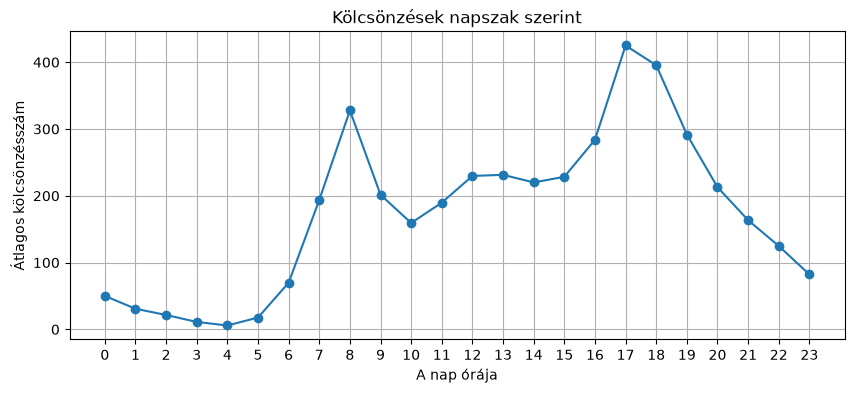

In [11]:
orankenti_atlag = y_tanito.groupby(X_tanito["hr"]).mean()

orankenti_atlag.plot(marker="o", figsize=(10, 4))
plt.xlabel("A nap órája")
plt.ylabel("Átlagos kölcsönzésszám")
plt.title("Kölcsönzések napszak szerint")
plt.xticks(range(24))
plt.grid()
plt.savefig("figures/napszakok.png", dpi=150, bbox_inches="tight")
plt.show()

## Munkanapok és nem munkanapok összehasonlítása

Külön vizsgáljuk a két csoport óránkénti átlagát. A különbség összefüggést mutat, önmagában nem bizonyítja az okát.

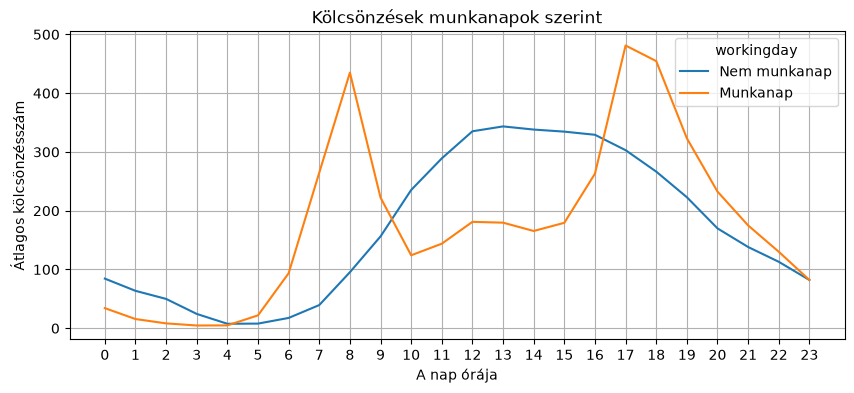

In [12]:
tanito = X_tanito.copy()
tanito["cnt"] = y_tanito

atlagok = tanito.groupby(["hr", "workingday"])["cnt"].mean().unstack()
atlagok = atlagok.rename(columns={0: "Nem munkanap", 1: "Munkanap"})

atlagok.plot(figsize=(10, 4))
plt.xlabel("A nap órája")
plt.ylabel("Átlagos kölcsönzésszám")
plt.title("Kölcsönzések munkanapok szerint")
plt.xticks(range(24))
plt.grid()
plt.savefig("figures/munkanapok.png", dpi=150, bbox_inches="tight")
plt.show()

## Hőmérséklet és kölcsönzések

A pontdiagramon egy pont egy órát jelöl. A normalizált hőmérséklet és a kölcsönzésszám kapcsolatát vizsgáljuk.

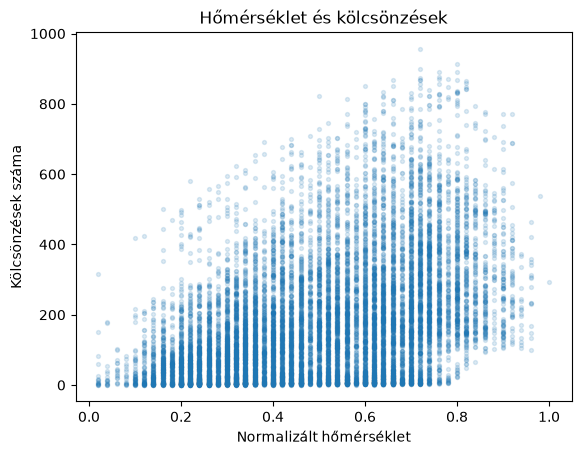

In [13]:
plt.scatter(X_tanito["temp"], y_tanito, alpha=0.15, s=8)
plt.xlabel("Normalizált hőmérséklet")
plt.ylabel("Kölcsönzések száma")
plt.title("Hőmérséklet és kölcsönzések")
plt.savefig("figures/homerseklet.png", dpi=150, bbox_inches="tight")
plt.show()

## Időjárási kategóriák összehasonlítása

Kategóriánként megjelenítjük a megfigyelések számát és az átlagos kölcsönzésszámot; kevés megfigyelés mellett az átlag bizonytalanabb.

In [14]:
tanito.groupby("weathersit")["cnt"].agg(["count", "mean"])

,count,mean
weathersit,,
1,9251,190.310345
2,3468,158.348039
3,1181,99.977138
4,3,74.333333


## One-hot kódolás: időjárás

A tanítóadatok időjárási kategóriáit külön oszlopokká alakítjuk, hogy a modell ne kezelje őket egyszerű számskálaként.

In [16]:
from sklearn.preprocessing import OneHotEncoder

kodolo = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
kodolt = kodolo.fit_transform(X_tanito[["weathersit"]])

print("Kategóriák:", kodolo.categories_[0])
print("Első öt sor:\n", kodolt[:5])

Kategóriák: [1 2 3 4]
Első öt sor:
 [[1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]]


## A tesztadatok kódolása

A tanítóadatokon illesztett kódolóval alakítjuk át a tesztadatokat, így az oszlopok jelentése azonos marad.

In [18]:
kodolt_teszt = kodolo.transform(X_teszt[["weathersit"]])

print("Tanító mérete:", kodolt.shape)
print("Teszt mérete:", kodolt_teszt.shape)

Tanító mérete: (13903, 4)
Teszt mérete: (3476, 4)


## Több változó előfeldolgozása

A ColumnTransformer a kiválasztott kategóriákat kódolja, a többi változót megtartja. A kódolót csak a tanítóadatokra illesztjük.

In [19]:
from sklearn.compose import ColumnTransformer

kategoriak = ["season", "mnth", "hr", "weekday", "weathersit"]

elofeldolgozo = ColumnTransformer(
    [("kategoriak", OneHotEncoder(handle_unknown="ignore"), kategoriak)],
    remainder="passthrough"
)

X_tanito_kodolt = elofeldolgozo.fit_transform(X_tanito)
X_teszt_kodolt = elofeldolgozo.transform(X_teszt)

print(X_tanito_kodolt.shape)
print(X_teszt_kodolt.shape)

(13903, 58)
(3476, 58)


## Az előállított oszlopok nevei

Megnézzük, melyik új oszlop melyik kategóriához tartozik, és mely változók maradtak változatlanok.

In [20]:
elofeldolgozo.get_feature_names_out()

array(['kategoriak__season_1', 'kategoriak__season_2',
       'kategoriak__season_3', 'kategoriak__season_4',
       'kategoriak__mnth_1', 'kategoriak__mnth_2', 'kategoriak__mnth_3',
       'kategoriak__mnth_4', 'kategoriak__mnth_5', 'kategoriak__mnth_6',
       'kategoriak__mnth_7', 'kategoriak__mnth_8', 'kategoriak__mnth_9',
       'kategoriak__mnth_10', 'kategoriak__mnth_11',
       'kategoriak__mnth_12', 'kategoriak__hr_0', 'kategoriak__hr_1',
       'kategoriak__hr_2', 'kategoriak__hr_3', 'kategoriak__hr_4',
       'kategoriak__hr_5', 'kategoriak__hr_6', 'kategoriak__hr_7',
       'kategoriak__hr_8', 'kategoriak__hr_9', 'kategoriak__hr_10',
       'kategoriak__hr_11', 'kategoriak__hr_12', 'kategoriak__hr_13',
       'kategoriak__hr_14', 'kategoriak__hr_15', 'kategoriak__hr_16',
       'kategoriak__hr_17', 'kategoriak__hr_18', 'kategoriak__hr_19',
       'kategoriak__hr_20', 'kategoriak__hr_21', 'kategoriak__hr_22',
       'kategoriak__hr_23', 'kategoriak__weekday_0',
       'kateg

## Példa: előfeldolgozás és modell egy pipeline-ban

A pipeline a tanítóadatokból illeszti az előfeldolgozást és a példaként használt lineáris regressziót. Ez még nem a végső modellválasztás.

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

pelda = Pipeline([
    ("elofeldolgozas", elofeldolgozo),
    ("modell", LinearRegression())
])

pelda.fit(X_tanito, y_tanito)
print("A modell betanult.")

A modell betanult.


## Időrendi keresztvalidáció

Három időrendi tanító–validációs felosztással számolunk MAE-t. A teljes pipeline minden körben az adott tanítórészből tanul, a végső teszthalmaz külön marad.

In [22]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

idobeli_cv = TimeSeriesSplit(n_splits=3)

mae = -cross_val_score(
    pelda,
    X_tanito,
    y_tanito,
    cv=idobeli_cv,
    scoring="neg_mean_absolute_error"
)

print("MAE értékek:", mae)
print("Átlagos MAE:", mae.mean())

MAE értékek: [ 74.5859298   71.29545354 106.45669212]
Átlagos MAE: 84.11269181846471


## A legnagyobb kölcsönzésszámok

Megnézzük a tanítóadatok tíz legnagyobb értékének dátumát és óráját. A nagy érték önmagában nem bizonyít adathibát.

In [23]:
adatok.loc[X_tanito.index].nlargest(10, "cnt")[["dteday", "hr", "cnt"]]

,dteday,hr,cnt
10622,2012-03-23,17,957
13596,2012-07-25,17,913
12900,2012-06-26,17,900
13597,2012-07-25,18,891
13765,2012-08-01,18,891
13573,2012-07-24,18,877
11916,2012-05-16,17,873
13213,2012-07-09,18,872
13236,2012-07-10,17,872
12444,2012-06-07,17,869


## Korábbi fájlkészítési lépés

Ez az üres cella egy korábbi fájlírási művelet kimenetét őrzi; futtatható kódot már nem tartalmaz.

Overwriting data_preparation.py


## Az adat-előkészítő függvény ellenőrzése

A külön Python-fájl függvényével újra előállítjuk a felosztást, és ellenőrizzük a méreteket.

In [26]:
from data_preparation import adatok_elokeszitese

X_proba, X_teszt_proba, y_proba, y_teszt_proba = adatok_elokeszitese()

print("Tanító:", X_proba.shape)
print("Teszt:", X_teszt_proba.shape)

Tanító: (13903, 12)
Teszt: (3476, 12)


## Korábbi fájlbővítési lépés

Ez az üres cella egy korábbi fájlbővítés kimenetét őrzi; futtatható kódot már nem tartalmaz.

Appending to data_preparation.py


## A külön fájlban lévő kódoló ellenőrzése

Újratöltjük a módosított modult, majd a tanítóadatokon illesztett kódolót a tesztadatokra is alkalmazzuk.

In [28]:
import importlib
import data_preparation

importlib.reload(data_preparation)

kodolo_proba = data_preparation.elofeldolgozo_letrehozasa()

print("Tanító:", kodolo_proba.fit_transform(X_proba).shape)
print("Teszt:", kodolo_proba.transform(X_teszt_proba).shape)

Tanító: (13903, 58)
Teszt: (3476, 58)


## Az ábrák mappája

Létrehozzuk a figures mappát, ha még nem létezik; ide kerülnek a megosztható PNG-ábrák.

In [29]:
from pathlib import Path

Path("figures").mkdir(exist_ok=True)

## Az eloszlásábra fájljának ellenőrzése

Ellenőrizzük, hogy a hisztogramot tartalmazó PNG-fájl létezik-e.

In [ ]:
Path("figures/kolcsonzes_eloszlas.png").exists()

## A mentés visszaellenőrzése

Az exists() eredménye True, ha a megadott fájl megtalálható.

In [31]:
Path("figures/kolcsonzes_eloszlas.png").exists()

True

## A napszakos ábra ellenőrzése

Ellenőrizzük, hogy a napszakonkénti átlagok ábrája elérhető-e fájlként.

In [ ]:
Path("figures/napszakok.png").exists()

## A munkanapos ábra ellenőrzése

Ellenőrizzük, hogy a munkanapok összehasonlításának ábrája elérhető-e fájlként.

In [ ]:
Path("figures/munkanapok.png").exists()

## A hőmérsékleti ábra ellenőrzése

Ellenőrizzük, hogy a hőmérséklet és a kölcsönzésszám pontdiagramja elérhető-e fájlként.

In [ ]:
Path("figures/homerseklet.png").exists()

## A mentett ábrák listája

Felsoroljuk a figures mappában található PNG-fájlokat.

In [35]:
sorted(p.name for p in Path("figures").glob("*.png"))

['homerseklet.png',
 'kolcsonzes_eloszlas.png',
 'munkanapok.png',
 'napszakok.png']

## Dobozábra és szélső értékek

A seaborn dobozábrája munkanap szerint mutatja az eloszlást. A különálló pontok statisztikailag szélsők, de nem feltétlenül hibásak.

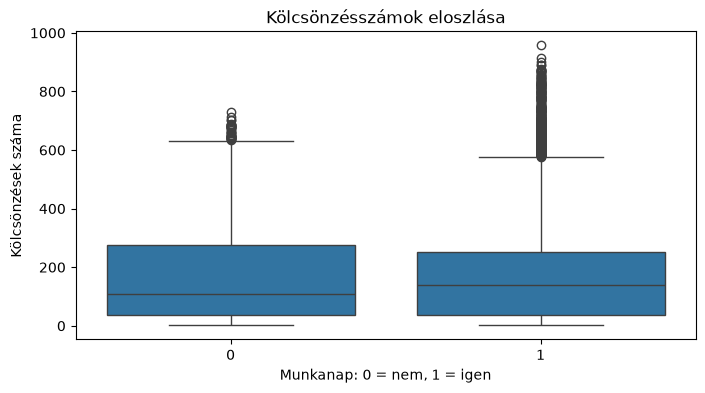

In [36]:
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.boxplot(data=tanito, x="workingday", y="cnt")
plt.xlabel("Munkanap: 0 = nem, 1 = igen")
plt.ylabel("Kölcsönzések száma")
plt.title("Kölcsönzésszámok eloszlása")
plt.savefig("figures/dobozabra.png", dpi=150, bbox_inches="tight")
plt.show()

## Kiugró értékek

A dobozábrán több szélső érték látható. A legnagyobb
tanítóadatban szereplő érték 957 kölcsönzés volt 17 órakor.
Az értékeket nem töröltük, mert valós forgalmi csúcsot is
jelenthetnek, és nem találtunk bizonyítékot arra, hogy hibásak.

## Adatok és előfeldolgozás

Az UCI Bike Sharing adathalmaz 17 379 óránkénti megfigyelést
tartalmaz 2011–2012-ből. Az előrejelzendő érték a kölcsönzések
száma, a `cnt` oszlop.

Nem találtunk hiányzó értéket vagy ismétlődő dátum–óra párost.
Az adatokat időrendben osztottuk fel: 13 903 sor tanításra,
3 476 sor tesztelésre szolgál.

A `casual` és `registered` oszlopokat kizártuk, mert összegük
maga a megjósolandó `cnt`. A kategóriákat one-hot kódolással
készítettük elő.
